In [8]:
 !pip install shap lime

In [9]:
# ---------------------------------------------------------
# Tasks 1 & 2: Dataset Acquisition & Load Dataset
# ---------------------------------------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, roc_auc_score

import shap
import lime
import lime.lime_tabular

url = 'https://raw.githubusercontent.com/dimikara/Survival-Prediction-of-Patients-with-Heart-Failure/master/heart_failure_clinical_records_dataset.csv'
try:
    df = pd.read_csv(url)
except Exception:
    import glob
    csv_files = glob.glob('*.csv')
    if csv_files:
        df = pd.read_csv(csv_files[0])
    else:
        from google.colab import files
        uploaded = files.upload()
        df = pd.read_csv(next(iter(uploaded)))

print('--- First 5 Rows ---')
print(df.head())

--- First 5 Rows ---
    age  anaemia  creatinine_phosphokinase  diabetes  ejection_fraction  \
0  75.0        0                       582         0                 20   
1  55.0        0                      7861         0                 38   
2  65.0        0                       146         0                 20   
3  50.0        1                       111         0                 20   
4  65.0        1                       160         1                 20   

   high_blood_pressure  platelets  serum_creatinine  serum_sodium  sex  \
0                    1  265000.00               1.9           130    1   
1                    0  263358.03               1.1           136    1   
2                    0  162000.00               1.3           129    1   
3                    0  210000.00               1.9           137    1   
4                    0  327000.00               2.7           116    0   

   smoking  time  DEATH_EVENT  
0        0     4            1  
1        0     6   

In [10]:
# ---------------------------------------------------------
# Task 3: Summarize Dataset
# ---------------------------------------------------------
print(f'Rows: {df.shape[0]}, Columns: {df.shape[1]}')
print('\nData Types:')
print(df.dtypes)
print('\nMissing Values Count:')
print(df.isnull().sum())

Rows: 299, Columns: 13

Data Types:
age                         float64
anaemia                       int64
creatinine_phosphokinase      int64
diabetes                      int64
ejection_fraction             int64
high_blood_pressure           int64
platelets                   float64
serum_creatinine            float64
serum_sodium                  int64
sex                           int64
smoking                       int64
time                          int64
DEATH_EVENT                   int64
dtype: object

Missing Values Count:
age                         0
anaemia                     0
creatinine_phosphokinase    0
diabetes                    0
ejection_fraction           0
high_blood_pressure         0
platelets                   0
serum_creatinine            0
serum_sodium                0
sex                         0
smoking                     0
time                        0
DEATH_EVENT                 0
dtype: int64


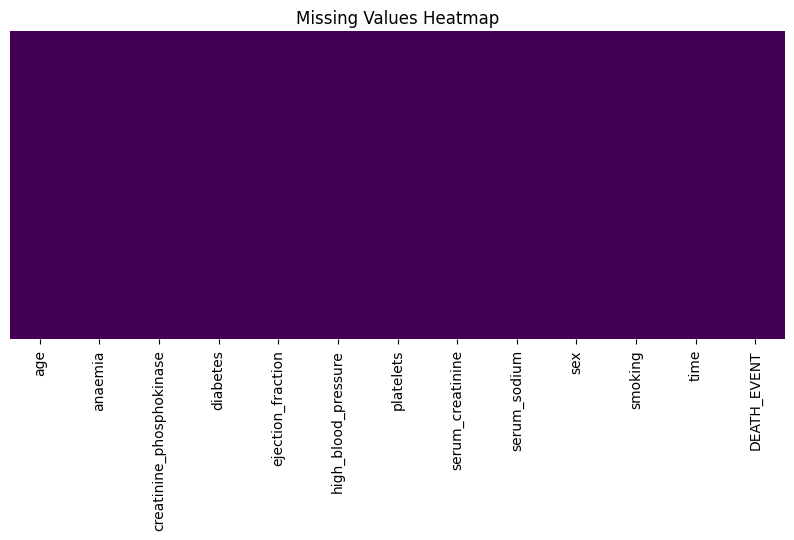

In [11]:
# ---------------------------------------------------------
# Task 4: Visualize Missing Values
# ---------------------------------------------------------
plt.figure(figsize=(10, 4))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis', yticklabels=False)
plt.title('Missing Values Heatmap')
plt.show()

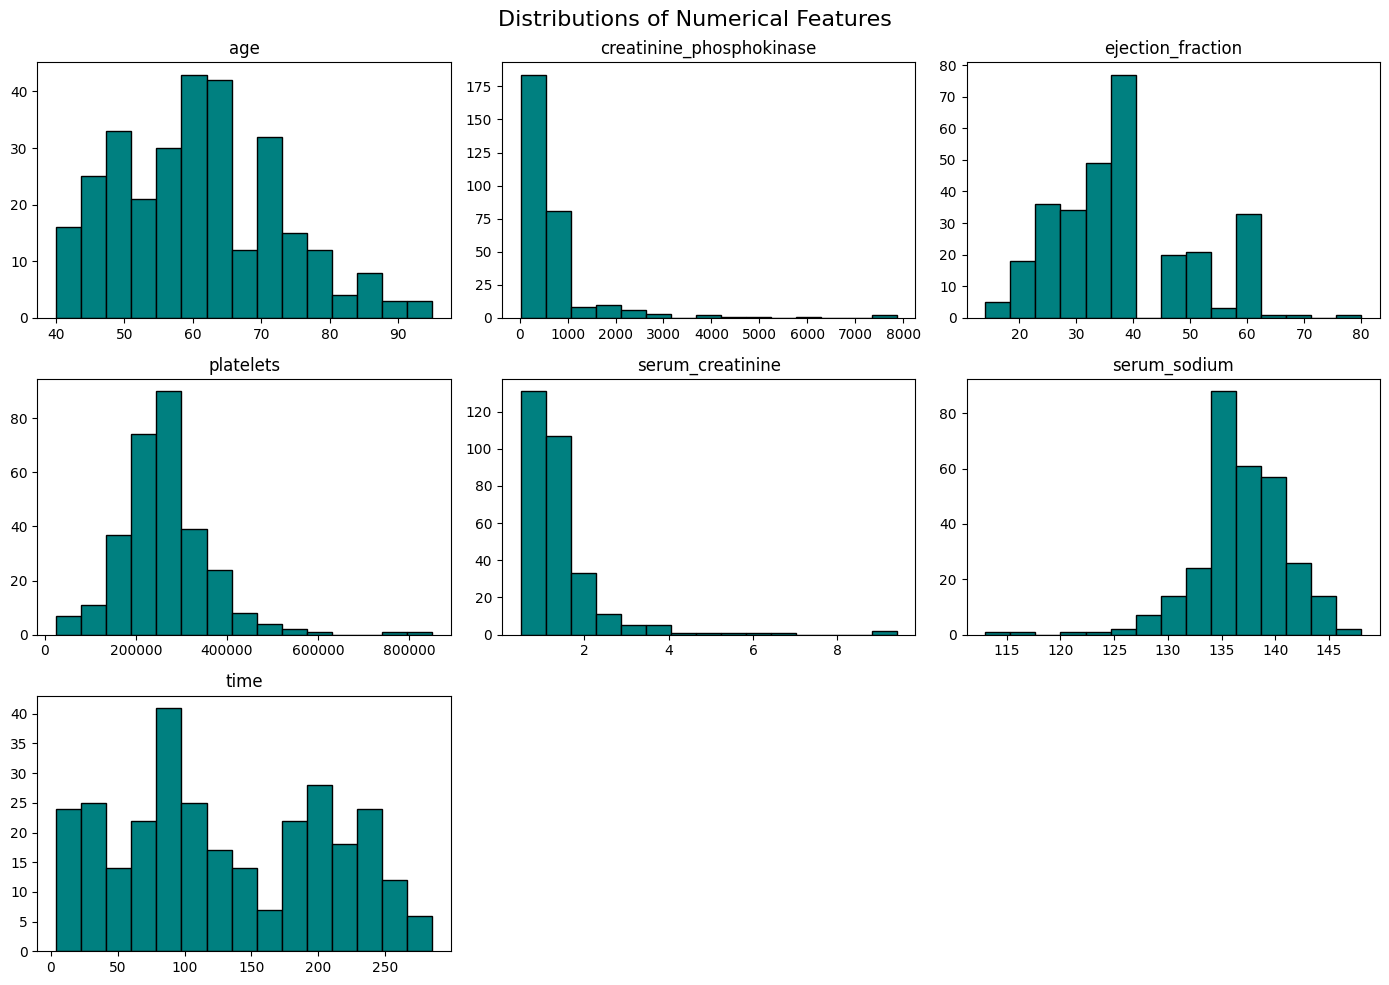

In [12]:
# ---------------------------------------------------------
# Task 5: Plot Distributions
# ---------------------------------------------------------
num_cols = ['age', 'creatinine_phosphokinase', 'ejection_fraction', 'platelets', 'serum_creatinine', 'serum_sodium', 'time']
df[num_cols].hist(bins=15, figsize=(14, 10), grid=False, color='teal', edgecolor='black')
plt.suptitle('Distributions of Numerical Features', fontsize=16)
plt.tight_layout()
plt.show()

In [13]:
# ---------------------------------------------------------
# Tasks 6, 7 & 8: Impute Missing Values
# ---------------------------------------------------------
for col in df.columns:
    if df[col].isnull().sum() > 0:
        if df[col].dtype in ['float64', 'int64']:
            df[col].fillna(df[col].median(), inplace=True)
        else:
            df[col].fillna(df[col].mode()[0], inplace=True)

# ---------------------------------------------------------
# Tasks 9 & 10: Correct Inconsistencies & Remove Outliers
# ---------------------------------------------------------
# Fix invalid values (e.g. negative age)
df['age'] = df['age'].apply(lambda x: np.nan if x < 0 else x)
df['age'].fillna(df['age'].median(), inplace=True)

# Handle extreme outliers using IQR method
Q1 = df['serum_creatinine'].quantile(0.25)
Q3 = df['serum_creatinine'].quantile(0.75)
IQR = Q3 - Q1
df = df[(df['serum_creatinine'] >= (Q1 - 1.5 * IQR)) & (df['serum_creatinine'] <= (Q3 + 1.5 * IQR))]
print(f'Cleaned Dataset Shape: {df.shape}')

Cleaned Dataset Shape: (270, 13)


/tmp/ipykernel_664/47354145.py:16: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['age'].fillna(df['age'].median(), inplace=True)


In [14]:
# ---------------------------------------------------------
# Tasks 11, 12 & 13: Feature Engineering
# ---------------------------------------------------------
# Task 12: Bin age into groups (<40, 40-60, >60)
df['age_group'] = pd.cut(df['age'], bins=[0, 40, 60, np.inf], labels=['<40', '40-60', '>60'])

# Task 13: Risk score feature
raw_risk = df['serum_creatinine'] / (df['ejection_fraction'] + 1e-5)
df['risk_score'] = (raw_risk - raw_risk.min()) / (raw_risk.max() - raw_risk.min())

In [15]:
# ---------------------------------------------------------
# Tasks 14 & 15: Encode Categorical & Normalize Features
# ---------------------------------------------------------
# One-Hot Encoding
df = pd.get_dummies(df, columns=['age_group'], drop_first=False)

X = df.drop(columns=['DEATH_EVENT'])
y = df['DEATH_EVENT']

# Min-Max Normalization
scaler = MinMaxScaler()
num_feats = ['age', 'creatinine_phosphokinase', 'ejection_fraction', 'platelets', 'serum_creatinine', 'serum_sodium', 'time', 'risk_score']
X[num_feats] = scaler.fit_transform(X[num_feats])
X = X.astype(float)

X.head()

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,risk_score,age_group_<40,age_group_40-60,age_group_>60
0,0.636364,0.0,0.070489,0.0,0.090909,1.0,0.290823,0.875,0.485714,1.0,0.0,0.000000,0.744961,0.0,0.0,1.0
1,0.272727,0.0,1.000000,0.0,0.363636,0.0,0.288833,0.375,0.657143,1.0,0.0,0.007117,0.154481,0.0,1.0,0.0
2,0.454545,0.0,0.014813,0.0,0.090909,0.0,0.165960,0.500,0.457143,1.0,1.0,0.010676,0.476775,0.0,0.0,1.0
3,0.181818,1.0,0.010344,0.0,0.090909,0.0,0.224148,0.875,0.685714,1.0,0.0,0.010676,0.744961,0.0,1.0,0.0
5,0.909091,1.0,0.002171,0.0,0.393939,1.0,0.216875,1.000,0.542857,1.0,1.0,0.014235,0.365031,0.0,0.0,1.0


In [16]:
# ---------------------------------------------------------
# Task 16: Train Classifier
# ---------------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print(f'Accuracy: {accuracy_score(y_test, y_pred):.4f}')
print(f'ROC-AUC Score: {roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]):.4f}\n')
print(classification_report(y_test, y_pred))

Accuracy: 0.8148
ROC-AUC Score: 0.8964

              precision    recall  f1-score   support

           0       0.83      0.92      0.88        38
           1       0.75      0.56      0.64        16

    accuracy                           0.81        54
   macro avg       0.79      0.74      0.76        54
weighted avg       0.81      0.81      0.81        54



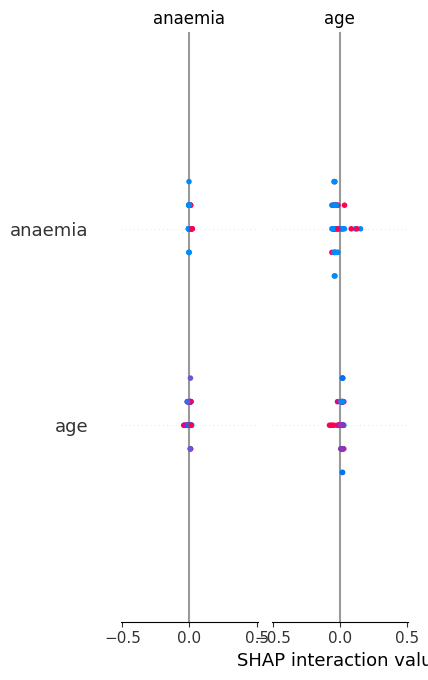

/usr/local/lib/python3.13/dist-packages/lime/discretize.py:110: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  ret[feature] = int(self.lambdas[feature](ret[feature]))
/usr/local/lib/python3.13/dist-packages/lime/discretize.py:110: FutureWarning: Series.__setitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To set a value by position, use `ser.iloc[pos] = value`
  ret[feature] = int(self.lambdas[feature](ret[feature]))
/usr/local/lib/python3.13/dist-packages/lime/lime_tabular.py:544: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.

In [17]:
# ---------------------------------------------------------
# Task 17: Apply SHAP & LIME Interpretability
# ---------------------------------------------------------
# 1. SHAP Interpretability
shap.initjs()
explainer_shap = shap.TreeExplainer(model)
shap_values = explainer_shap.shap_values(X_test)

vals = shap_values[1] if isinstance(shap_values, list) else shap_values
shap.summary_plot(vals, X_test)

# 2. LIME Interpretability
explainer_lime = lime.lime_tabular.LimeTabularExplainer(
    training_data=np.array(X_train),
    feature_names=X_train.columns,
    class_names=['Survived', 'Deceased'],
    mode='classification',
    random_state=42
)

exp = explainer_lime.explain_instance(
    data_row=X_test.iloc[0],
    predict_fn=model.predict_proba,
    num_features=8
)
exp.show_in_notebook(show_table=True)